# Overnight jumps that depend on the previous session

In `basic_jump_equation.ipynb` the data are a geometric Brownian motion (GBM). There each
overnight jump is independent of the session before it, so the basic model's $\beta(u)$ is zero.
To test whether the model can detect a dependence, we need data in which the jump depends on
yesterday's intraday curve in a known way.

This notebook builds such data. The jump depends on how the previous session *ended*: on the
trend of its last 20%, measured by a least-squares slope. Within the session, the first
half-hour's return predicts the last half-hour's
[[31]](../docs/references.md#ref-gao-etal-2018). The model here supposes that the late-session
trend carries on across the close. The intraday curves are the GBM's, unchanged; only the nights
are replaced.

With $P = 100\log S$, curves $X_t(s) = P_t(s) - P_t(0)$ on $s \in [0, 1]$, and a night of length
$T$:

$$
\begin{aligned}
X_t(s) &= 100\,m\,s + \sigma_\varepsilon W_t(s), && \sigma_\varepsilon = 100\,\sigma,\quad m = \nu - \sigma^2/2, \\
\hat b_{t-1} &= \text{least-squares slope of } X_{t-1}(s) \text{ on } s \text{ over } s \in [0.8, 1], \\
J_t &= 100\,m\,T + \kappa\,T\,(\hat b_{t-1} - 100\,m) + \sigma_\varepsilon\sqrt{T}\,Z_t, && Z_t \overset{\text{iid}}{\sim} N(0,1), \\
P_t(s) &= P_{t-1}(1) + J_t + X_t(s).
\end{aligned}
$$

The jump is the GBM's own jump (mean $100mT$, noise $\sigma_\varepsilon\sqrt T Z_t$) plus a
signal. The signal is a share $\kappa$ of how far yesterday's window slope sat from the drift,
carried on over the night. $\kappa = 0$ is the GBM, the null. $\kappa = 1$ carries the slope on in
full. The code is `jump.window_dgp`.

**Results.**

- The jump equation is exactly the basic functional model, with a $\beta(u)$ that is zero before
  0.8 and a sign-changing line on the window (§4).
- With 62 jumps and 8 principal components, the F test of $\beta = 0$ rejects at $\kappa = 0.5$
  (p = 0.0007) and $\kappa = 1$, but not at $\kappa = 0.25$ (p = 0.083). $\hat\beta$ finds the
  late-session effect and its sign, but not where the window starts (§5).
- Over 100 simulated quarters, truncFLR method A is the most accurate estimator and the only one
  that locates the window, though with a long tail of bad fits. Method B fails because $\beta$
  changes sign inside the window. The fdaSP group lasso is stable but almost never sets any part
  of $\hat\beta$ to zero (§6).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from joblib import Parallel, delayed

from fts_research.bench import study
from fts_research.core import style
from fts_research.core.quadrature import quadrature_weights
from fts_research.far.far_est import fpca
from fts_research.fdaSP import SBC
from fts_research.jump import window_dgp as wd

style.use(plt)
BLUE = style.CATEGORICAL[0]

## 1. Simulation

| parameter | value | |
|---|---|---|
| sessions, bars per session | 63, 390 | one quarter of one-minute data |
| $S_0$, $\sigma$, $\nu$ | 100, 0.01, $2.5\times10^{-4}$ | as in the null notebook |
| $T$ | 0.25 | night length in session units |
| window | $[0.8, 1]$ | the last 78 minutes |
| $\kappa$ | 0, 0.25, 0.5, 1 | from the null to full carry-over |

- **One normal draw per night.** $J_t$ is $100\times$ the log move of a GBM over the night, with
  volatility $\sigma$ and log drift $m + \kappa(\hat b_{t-1}/100 - m)$. That move is exactly
  normal, so no overnight path is simulated.
- **Burn-in.** The first jump reads an extra session-0 curve, which is not part of the sample.
- **Common random numbers.** Every $\kappa$ uses the same seed, so the curves and $Z$ are the
  same in each run and the jumps differ only by the signal.

In [2]:
n_days, n_bars = 63, 390
S0, sigma, T, nu = 100.0, 0.01, 0.25, 2.5e-4
start = 0.8                         # the window [0.8, 1]: the last 20% of the session
w = 1 - start
KAPPAS = (0.0, 0.25, 0.5, 1.0)
gbm = dict(n_days=n_days, n_bars=n_bars, S0=S0, sigma=sigma, T=T, nu=nu)

sims = {k: wd.window_jump_sessions(**gbm, start=start, kappa=k, rng=np.random.default_rng(0))
        for k in KAPPAS}
sim = sims[1.0]
s, X, X0 = sim["s"], sim["X"], sim["X0"]
on = s >= start - 1e-12                        # grid points in the window
before = np.vstack([X0, X[:-1]])               # the curve before each jump
b = sim["slope"]                               # bhat_{t-1}, one per jump

## 2. The window slope $\hat b$

The window $[0.8, 1]$ holds the grid points $s_k = k/390$, $k = 312, \dots, 390$. $\hat b_{t-1}$ is
the OLS slope of $X_{t-1}(s_k)$ on $s_k$ over these points, so it is a fixed linear functional of
yesterday's curve:

$$
\hat b_{t-1} = \sum_k c_k\,X_{t-1}(s_k), \qquad c_k = \frac{s_k - \bar s}{\sum_j (s_j - \bar s)^2}
\ \text{ in the window}, \quad c_k = 0 \text{ before it}.
$$

The drift $100m$ is the same every day, so the part of the jump that changes from day to day is
the direction the price actually moved in over the last 78 minutes. The figure shows the fitted
line on the sessions with the steepest late rise and the steepest late fall.

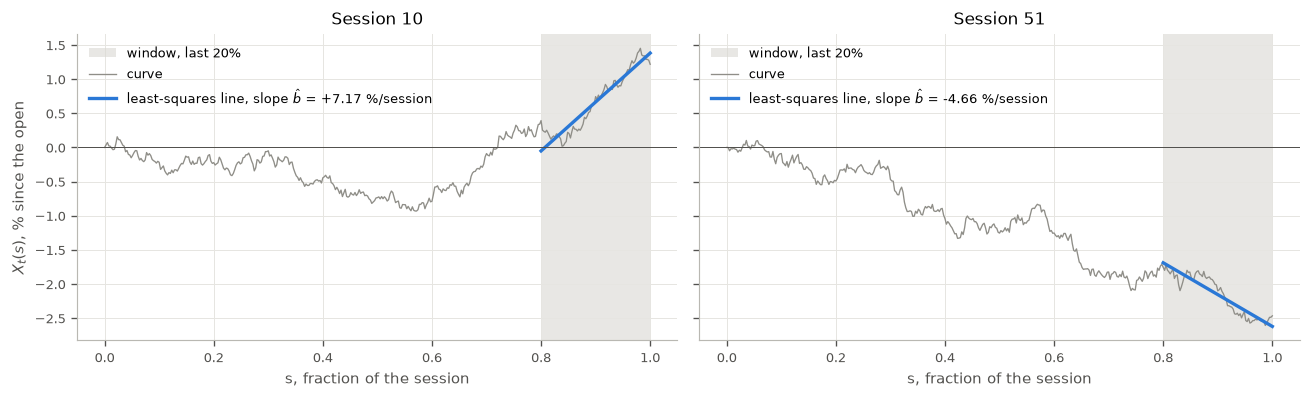

In [3]:
days = [int(np.argmax(b[1:])) + 1, int(np.argmin(b[1:])) + 1]   # steepest up and down

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, t in zip(axes, days):
    x = before[t]
    intercept = x[on].mean() - b[t] * s[on].mean()
    ax.axvspan(start, 1, color=style.BAND, alpha=0.6, lw=0, label="window, last 20%")
    ax.plot(s, x, color=style.CONTROL, lw=0.8, label="curve")
    ax.plot(s[on], intercept + b[t] * s[on], color=BLUE, lw=2,
            label=fr"least-squares line, slope $\hat b$ = {b[t]:+.2f} %/session")
    ax.axhline(0, color=style.MUTED, lw=0.6)
    ax.set_title(f"Session {t}")
    ax.set_xlabel("s, fraction of the session")
    ax.legend(loc="upper left")
axes[0].set_ylabel(r"$X_t(s)$, % since the open")
fig.tight_layout()
style.save_figure(fig, "window_jump_slope")
plt.show()

## 3. The jumps

Each panel plots the 63 jumps against the previous session's window slope, one panel per $\kappa$.
The dashed line is the true conditional mean, $100mT(1-\kappa) + \kappa T\,\hat b_{t-1}$. The
panel titles give the true $R^2$, the share of the jump's variance that the previous session
predicts.

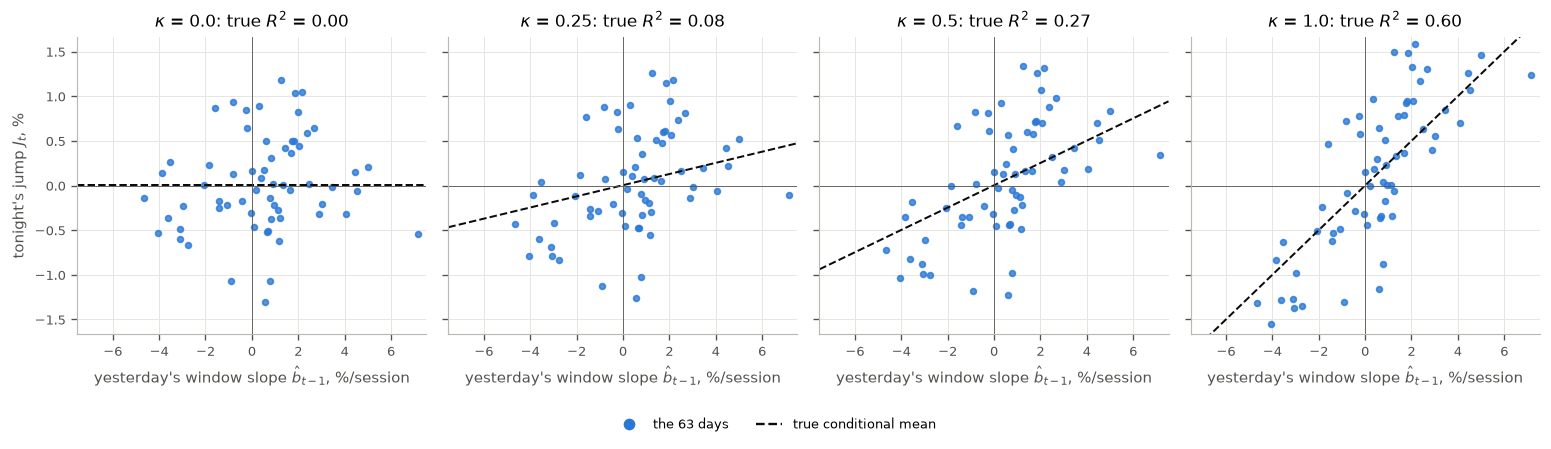

In [4]:
lim_b = 1.05 * np.abs(b).max()
lim_j = 1.05 * max(np.abs(sims[k]["J"]).max() for k in KAPPAS)
xs = np.array([-lim_b, lim_b])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True, sharey=True)
for ax, k in zip(axes, KAPPAS):
    tr = wd.window_jump_truth(s, sigma, T, nu, start, kappa=k)
    ax.plot(b, sims[k]["J"], "o", ms=3.5, color=BLUE, alpha=0.8)
    ax.plot(xs, tr["alpha"] + tr["kappa_T"] * xs, color=style.INK, lw=1.2, ls="--")
    ax.axhline(0, color=style.MUTED, lw=0.5)
    ax.axvline(0, color=style.MUTED, lw=0.5)
    ax.set_xlim(-lim_b, lim_b)
    ax.set_ylim(-lim_j, lim_j)
    ax.set_title(fr"$\kappa$ = {k}: true $R^2$ = {tr['r2']:.2f}")
    ax.set_xlabel(r"yesterday's window slope $\hat b_{t-1}$, %/session")
axes[0].set_ylabel(r"tonight's jump $J_t$, %")
fig.legend(handles=[plt.Line2D([], [], color=BLUE, marker="o", ls="", label="the 63 days"),
                    plt.Line2D([], [], color=style.INK, ls="--", label="true conditional mean")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_jump_scatter")
plt.show()

At $\kappa = 0$ the cloud is flat. As $\kappa$ grows it tilts along the true line, while its
vertical spread stays the same. Because $Z$ is shared across runs, each point moves straight up or
down from one panel to the next.

## 4. The model's $\beta(u)$

As the grid gets finer, the slope becomes an integral against yesterday's curve,
$\hat b_{t-1} = \frac{12}{w^3}\int_{0.8}^1 (u - 0.9)\,X_{t-1}(u)\,\mathrm{d}u$, with $w = 0.2$.
The jump equation is therefore exactly the basic model,

$$
J_t = \alpha + \int_0^1 \beta(u)\,X_{t-1}(u)\,\mathrm{d}u + \eta_t, \qquad
\beta(u) = \kappa T\,\frac{12\,(u - 0.9)}{0.2^3}\,\mathbf 1\{u \ge 0.8\},
$$

with $\alpha = 100mT(1-\kappa)$ and $\eta_t = \sigma_\varepsilon\sqrt T Z_t$. $\beta(u)$ is zero
before 0.8 and a line on the window, from $-37.5\kappa$ at 0.8 through zero at 0.9 to
$+37.5\kappa$ at the close; it is drawn as the black line in the figures of §5 and §6. The jump at
$u = 0.8$ is a genuine discontinuity, which a fit built from smooth basis functions cannot
reproduce.

## 5. Fitting the basic model

**Method.** Expand yesterday's curve in its empirical functional principal components,
$X_{t-1}(u) = \bar X(u) + \sum_k \hat\xi_{t-1,k}\,\hat\phi_k(u)$. The functional term becomes a
sum over the scores,
$\int_0^1 \beta(u)\,X_{t-1}(u)\,\mathrm{d}u = \text{const} + \sum_k d_k\,\hat\xi_{t-1,k}$ with
$d_k = \langle \beta, \hat\phi_k\rangle$. Keeping the first $M$ components gives a linear regression,

$$
J_t = a + \sum_{k=1}^{M} d_k\,\hat\xi_{t-1,k} + e_t, \qquad t = 2, \dots, 63,
\qquad \hat\beta(u) = \sum_{k=1}^{M} \hat d_k\,\hat\phi_k(u).
$$

With Gaussian errors, the conditional MLE of this regression is OLS. The components are those
of the 62 curves $X_1, \dots, X_{62}$ that serve as regressors. $\beta = 0$ is tested with the
F test of $d_1 = \dots = d_M = 0$. Under the null the jumps are i.i.d. normal and independent of
the curves, so the test is exact.

**Choosing $M$.** The fit can only recover the projection of $\beta$ onto the first $M$
components. For Brownian curves the components are known exactly:
$\phi_k(u) = \sqrt 2 \sin\big((k - \tfrac12)\pi u\big)$, with eigenvalues
$\lambda_k = \sigma_\varepsilon^2 / \big((k - \tfrac12)\pi\big)^2$. Component $k$ carries a share
$\lambda_k / \sum_j \lambda_j$ of the curve's variance and a share
$d_k^2\lambda_k / \sum_j d_j^2\lambda_j$ of the signal's variance. Neither share depends on
$\kappa$ or $\sigma$.

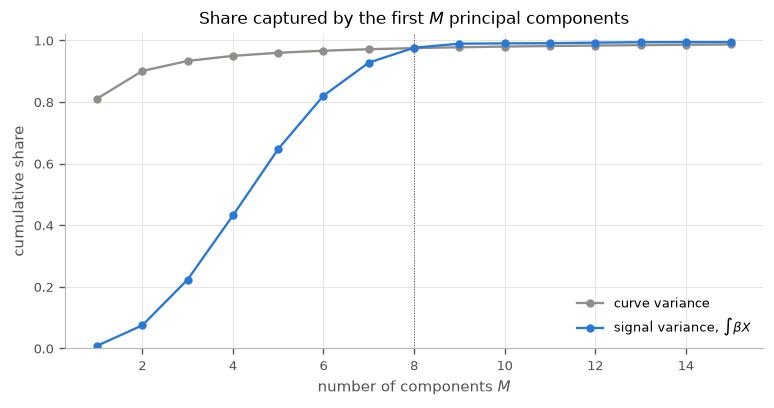

M = 1: 81.1% of the curve variance, 0.8% of the signal
M = 4: 95.0% of the curve variance, 43.1% of the signal
M = 8: 97.5% of the curve variance, 97.6% of the signal


In [5]:
qw = quadrature_weights(s)
k_all = np.arange(1, 201)
lam = 1 / ((k_all - 0.5) * np.pi) ** 2                    # eigenvalues for sigma_eps = 1
phi_bm = np.sqrt(2) * np.sin(np.outer(k_all - 0.5, np.pi * s))
d_bm = phi_bm @ (qw * wd.window_beta(s, start, kappa=1.0, T=T))
curve_share = np.cumsum(lam) / 0.5                         # total variance: int_0^1 u du = 1/2
signal_share = np.cumsum(d_bm**2 * lam) / (T * wd.window_slope_sd(s, start, 1.0)) ** 2

ks = np.arange(1, 16)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(ks, curve_share[:15], "o-", color=style.CONTROL, ms=4, label="curve variance")
ax.plot(ks, signal_share[:15], "o-", color=BLUE, ms=4, label=r"signal variance, $\int \beta X$")
ax.axvline(8, color=style.MUTED, lw=0.6, ls=":")
ax.set_ylim(0, 1.02)
ax.set_title(r"Share captured by the first $M$ principal components")
ax.set_xlabel(r"number of components $M$")
ax.set_ylabel("cumulative share")
ax.legend(loc="lower right")
style.save_figure(fig, "window_jump_components")
plt.show()

for m in (1, 4, 8):
    print(f"M = {m}: {curve_share[m - 1]:.1%} of the curve variance, "
          f"{signal_share[m - 1]:.1%} of the signal")

The first component carries 81% of the curve's variance but under 1% of the signal. The signal
sits in components 3 to 8. The reason is that $\hat b$ is a slope over the last 20% of the session, and
the low-order components $\sin\big((k - \tfrac12)\pi u\big)$ are nearly flat near $u = 1$. The
usual rule of keeping 95% of the curve's variance gives $M = 4$, which captures under half the
signal. We use $M = 8$, which captures 98%. Choosing $M$ this way uses knowledge of $\beta$; on
real data $M$ would have to come from a criterion such as cross-validation.
`window_jump_power.ipynb` chooses it from the data, at the signal strengths real data allow.

**Fit.** The cell fits the regression at each $\kappa$ on the same curves. It reports the F test
and the in-sample $R^2$, and it computes $\hat\beta(u)$ with a pointwise 95% band from the OLS
covariance of $\hat d$.

In [6]:
M = 8
pc = fpca(X[:-1], s, n_components=M)        # X_1..X_62, the curves that J_2..J_63 read
phi, scores = pc["phi"], pc["scores"]
D = np.column_stack([np.ones(n_days - 1), scores])
n, q = D.shape
DtD_inv = np.linalg.inv(D.T @ D)

fits, rows = {}, []
for k in KAPPAS:
    y = sims[k]["J"][1:]
    coef = DtD_inv @ D.T @ y
    resid = y - D @ coef
    s2 = resid @ resid / (n - q)
    tss = (y - y.mean()) @ (y - y.mean())
    F = (tss - resid @ resid) / M / s2
    beta_hat = coef[1:] @ phi
    se = np.sqrt(s2 * np.einsum("in,ij,jn->n", phi, DtD_inv[1:, 1:], phi))
    target = (phi @ (qw * wd.window_beta(s, start, k, T))) @ phi   # beta's projection
    fits[k] = beta_hat, se, target
    rows.append({"kappa": k, "F": F, "p-value": stats.f.sf(F, M, n - q),
                 "R2": 1 - resid @ resid / tss})
print(f"n = {n} jumps, M = {M} components, F on ({M}, {n - q}) degrees of freedom")
pd.DataFrame(rows).set_index("kappa").round(4)

n = 62 jumps, M = 8 components, F on (8, 53) degrees of freedom


,F,p-value,R2
kappa,,,
0.00,0.6485,0.7335,0.0892
0.25,1.8779,0.0831,0.2209
0.50,4.1366,0.0007,0.3844
1.00,11.4426,0.0000,0.6333


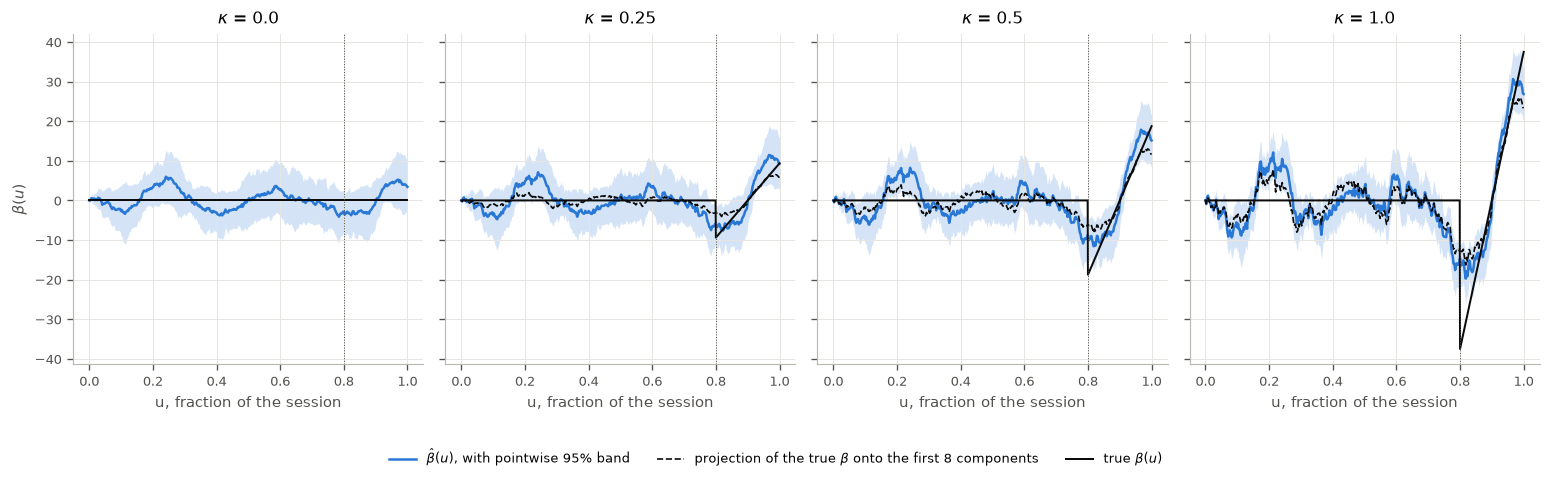

In [7]:
u = np.linspace(0, 1, 1001)                 # fine grid for the true beta, drop and all
tq = stats.t.ppf(0.975, n - q)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, k in zip(axes, KAPPAS):
    beta_hat, se, target = fits[k]
    ax.fill_between(s, beta_hat - tq * se, beta_hat + tq * se, color=BLUE, alpha=0.2, lw=0)
    ax.plot(s, beta_hat, color=BLUE, lw=1.5)
    ax.plot(s, target, color=style.INK, lw=1, ls="--")
    ax.plot(u, np.where(u >= start, k * T * 12 * (u - start - w / 2) / w**3, 0.0),
            color=style.INK, lw=1.2)
    ax.axvline(start, color=style.MUTED, lw=0.6, ls=":")
    ax.set_title(fr"$\kappa$ = {k}")
    ax.set_xlabel("u, fraction of the session")
axes[0].set_ylabel(r"$\beta(u)$")
fig.legend(handles=[
    plt.Line2D([], [], color=BLUE, lw=1.5, label=r"$\hat\beta(u)$, with pointwise 95% band"),
    plt.Line2D([], [], color=style.INK, lw=1, ls="--",
               label=fr"projection of the true $\beta$ onto the first {M} components"),
    plt.Line2D([], [], color=style.INK, lw=1.2, label=r"true $\beta(u)$")],
    loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
style.save_figure(fig, "window_jump_fit")
plt.show()

At $\kappa = 0$ the F test does not reject (p = 0.73). At $\kappa = 0.5$ and $\kappa = 1$ it
rejects firmly (p = 0.0007 and $p < 10^{-4}$). At $\kappa = 0.25$, where yesterday's curve
predicts 8% of the jump, 62 days are not enough (p = 0.083). The in-sample $R^2$ overstates the
fit: with 8 regressors and 62 jumps it averages $8/61 = 0.13$ even under the null.

$\hat\beta$ follows its target, the dashed projection, and the band covers that target almost
everywhere. The target is not $\beta$. Eight components cannot represent the discontinuity at
0.8, so the projection rounds off both the drop there and the peak at 1. It also wiggles before
0.8, where $\beta$ is zero, because the sample components of 62 rough Brownian paths are
themselves rough. The fit therefore finds the late-session effect and its sign, but not where
the window starts.

## 6. Estimators that can set $\hat\beta$ to zero

$\beta$ is zero on $[0, 0.8)$, but the fit of §5 spreads $\hat\beta$ over the whole session. Three
estimators can return a $\hat\beta$ that is exactly zero on part of the session:

| | assumes | how it finds the zero region | told |
|---|---|---|---|
| **untruncated** (§5) | nothing | it does not; $M = 8$ components, chosen knowing $\beta$ | – |
| **truncFLR, method A** [[37]](../docs/references.md#ref-hall-hooker-2016) | $\beta = 0$ outside one interval $[u, 1]$ | refits a principal component regression on the curves restricted to $[u, 1]$ at every candidate $u$; $\hat u$ minimises $\mathrm{RSS}(u) + n\lambda(1-u)^2$, and BIC picks $m \le 10$ components | the window ends at the close |
| **truncFLR, method B** [[37]](../docs/references.md#ref-hall-hooker-2016) | as A | fits once on $[0, 1]$ and zeroes that fit outside $[u, 1]$; $\hat u$ is the *first* interior local minimum of the same penalised RSS, scanning from $u = 1$ | as A |
| **fdaSP, group lasso** [[78]](../docs/references.md#ref-stefanucci-bernardi-canale-2025) | $\beta = 0$ on a union of intervals | 15 cubic B-splines with an overlap group lasso, which zeroes whole groups of coefficients | nothing |

Both truncFLR methods choose $\lambda$ by the paper's §3.2 criterion; the group lasso chooses it
by 10-fold cross-validation, and since it has no intercept the curves and jumps are centred first.
The methods are run through `bench.study`, as in `notebooks/basis_and_coef_comp.ipynb`.

Each fit is scored by its **relative ISE**, $\int(\hat\beta - \beta)^2 / \int\beta^2$, on which
$\hat\beta \equiv 0$ scores 1, and by its **implied window start** $\hat u$, the left end of the
last interval on which $\hat\beta \neq 0$ ($\hat u = 0$ if $\hat\beta$ is nowhere exactly zero).
The cell fits all four to the $\kappa = 1$ quarter of §5.

In [8]:
LAMBDAS = np.linspace(0.0, 1.0, 120)[1:]                  # truncFLR penalty grid, as in bench
METHODS = ("FPCA", "HH-A", "HH-B", "OGL")
LABEL = {"FPCA": "untruncated (§5)", "HH-A": "truncFLR, method A",
         "HH-B": "truncFLR, method B", "OGL": "fdaSP, group lasso"}


def fit_methods(X_prev, y, keep_state=False):
    # Every method on one quarter: beta_hat and its support (the points it does not zero).
    pc = fpca(X_prev, s, n_components=M)
    D = np.column_stack([np.ones(len(y)), pc["scores"]])
    coef = np.linalg.lstsq(D, y, rcond=None)[0]
    out = {"FPCA": {"beta": coef[1:] @ pc["phi"], "support": np.ones(s.size, bool)}}
    for name, state_fn, at_fn in (("HH-A", study.hh_a_state, study.hh_a_at),
                                  ("HH-B", study.hh_b_state, study.hh_b_at)):
        state = state_fn(X_prev, y, s, LAMBDAS, mirror=True)
        fit = at_fn(state, state["lam_hat"])
        out[name] = {"beta": fit["b_hat"], "support": fit["support"], "m": fit["m"],
                     "theta": fit["theta_hat"]}
        if keep_state:
            out[name]["state"] = state
    cv = SBC.cv_fit(X_prev - X_prev.mean(axis=0), y - y.mean(), s, n_basis=15, n_folds=10,
                    n_lambda=30, rng=0)
    out["OGL"] = {"beta": cv["beta"], "support": cv["support"]}
    return out


def true_beta(kappa):
    return np.where(s >= start, kappa * T * 12 * (s - start - w / 2) / w**3, 0.0)


def score_fits(fit, kappa):
    beta = true_beta(kappa)
    scale = np.trapezoid(beta**2, s)
    return {m: {"relative ISE": study.relative_ise(fit[m]["beta"], beta, s, scale),
                "u_hat": study.implied_endpoint(fit[m]["support"], s)} for m in METHODS}


one = fit_methods(X[:-1], sims[1.0]["J"][1:], keep_state=True)
null_ogl = SBC.find_regions(~one["OGL"]["support"], s)
print("group lasso: beta_hat is exactly zero on "
      + ", ".join(f"[{a:.3f}, {b:.3f}]" for a, b in null_ogl))
print(f"method B: max |beta_hat| = {np.abs(one['HH-B']['beta']).max():.0f}, "
      f"against max |beta| = {np.abs(true_beta(1.0)).max():.1f}")
pd.DataFrame(score_fits(one, 1.0)).T.rename(index=LABEL).round(3)

group lasso: beta_hat is exactly zero on [0.585, 0.667]
method B: max |beta_hat| = 296, against max |beta| = 37.5


,relative ISE,u_hat
untruncated (§5),0.376,0.000
"truncFLR, method A",0.374,0.792
"truncFLR, method B",6.623,0.990
"fdaSP, group lasso",0.229,0.669


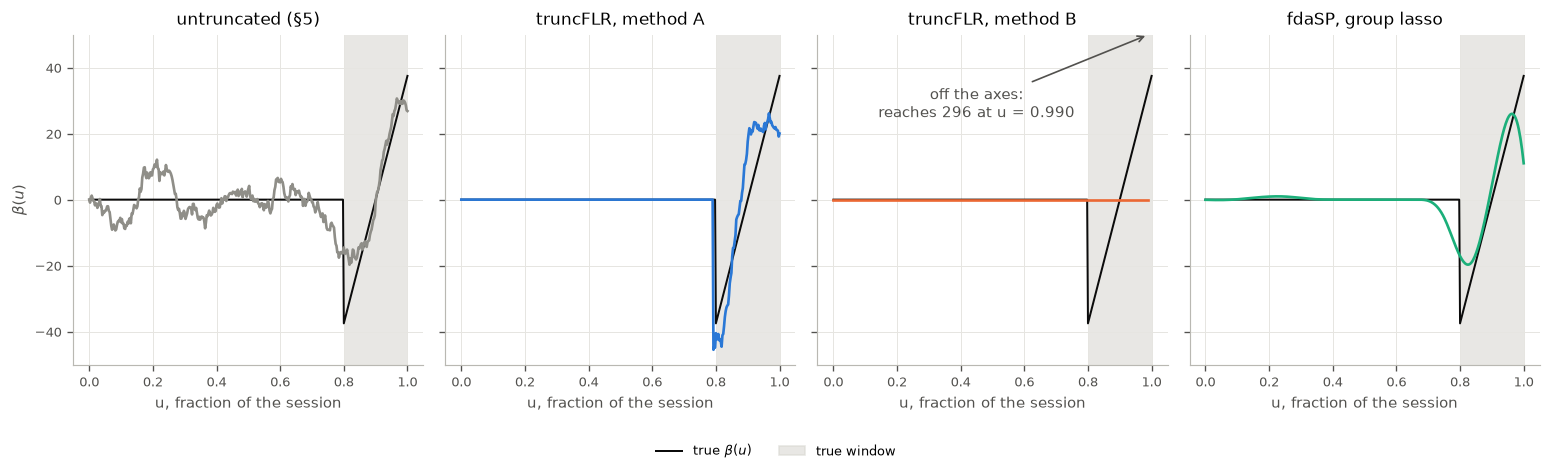

In [9]:
lo, hi = -50, 50
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, METHODS):
    shown, worst = style.clip_to(one[m]["beta"], lo, hi)
    ax.axvspan(start, 1, color=style.BAND, alpha=0.6, lw=0)
    ax.plot(s, true_beta(1.0), color=style.INK, lw=1.2)
    ax.plot(s, shown, color=style.METHOD_COLOUR[m], lw=1.6)
    if worst is not None:                  # point at the part of beta_hat that leaves the axes
        i = int(np.argmax(np.abs(one[m]["beta"])))
        edge = hi if one[m]["beta"][i] > 0 else lo
        ax.annotate(f"off the axes:\nreaches {one[m]['beta'][i]:.0f} at u = {s[i]:.3f}",
                    xy=(s[i], edge), xytext=(0.45, 0.5 * edge), ha="center",
                    color=style.MUTED, arrowprops=dict(arrowstyle="->", color=style.MUTED))
    ax.set_title(LABEL[m])
    ax.set_xlabel("u, fraction of the session")
    ax.set_ylim(lo, hi)
axes[0].set_ylabel(r"$\beta(u)$")
fig.legend(handles=[plt.Line2D([], [], color=style.INK, lw=1.2, label=r"true $\beta(u)$"),
                    plt.Rectangle((0, 0), 1, 1, color=style.BAND, alpha=0.6,
                                  label="true window")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_jump_methods")
plt.show()

Each panel shows one method's $\hat\beta$ against the true $\beta$ (black) and the true window
(shaded). Two things matter: where $\hat\beta$ becomes non-zero, and how closely it follows the
line inside the window.

- **Untruncated.** It follows the line on the window, but wiggles over the whole session before
  it, as in §5.
- **Method A** is exactly zero up to $\hat u = 0.792$, against the true 0.8, and drops at once, so
  it does reproduce the discontinuity. It is too flat near the close, though, and its relative
  ISE (0.374) is no better than the untruncated fit's (0.376): what it gains before 0.8 it loses
  inside the window.
- **Method B** keeps only $[0.990, 1]$ and fits the data with a spike there, so its relative ISE
  is 6.623. The figure below shows why.
- **Group lasso** has the smallest error (0.229). It is exactly zero only on $[0.585, 0.667]$
  and close to zero over most of $[0, 0.7]$, but it smooths the drop at 0.8 into a dip that
  starts before the window, so it does not locate the window.

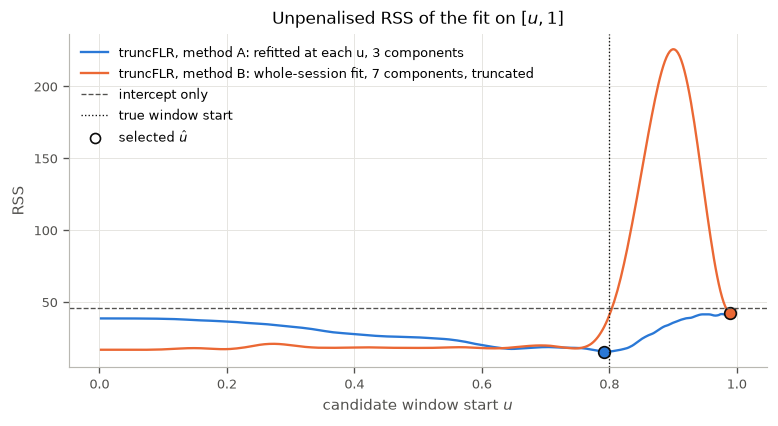

intercept only: RSS = 45.6
method A: RSS is smallest at u = 0.792
method B: RSS peaks at 226 at u = 0.900; its start at all 119 lambdas on the grid: 0.990


In [10]:
y_one = sims[1.0]["J"][1:]
tss = ((y_one - y_one.mean()) ** 2).sum()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
scan = {}
for m, how in (("HH-A", "refitted at each u, {} components"),
               ("HH-B", "whole-session fit, {} components, truncated")):
    state, fit = one[m]["state"], one[m]
    rss = state["rss"][fit["m"]] if m == "HH-A" else state["rss"]
    m_used = fit["m"] if m == "HH-A" else state["fpc"]["m"]
    u_scan = 1 - state["theta_grid"]
    i = int(np.argmin(np.abs(state["theta_grid"] - fit["theta"])))    # the selected start
    scan[m] = u_scan, rss, m_used
    ax.plot(u_scan, rss, color=style.METHOD_COLOUR[m], lw=1.4,
            label=f"{LABEL[m]}: {how.format(m_used)}")
    ax.plot(u_scan[i], rss[i], "o", color=style.METHOD_COLOUR[m], ms=7, mec=style.INK)
ax.axhline(tss, color=style.MUTED, lw=0.8, ls="--", label="intercept only")
ax.axvline(start, color=style.INK, lw=0.8, ls=":", label="true window start")
ax.plot([], [], "o", color="white", mec=style.INK, label=r"selected $\hat u$")
ax.set_title(r"Unpenalised RSS of the fit on $[u, 1]$")
ax.set_xlabel(r"candidate window start $u$")
ax.set_ylabel("RSS")
ax.legend(loc="upper left")
style.save_figure(fig, "window_jump_truncation_scan")
plt.show()

u_a, rss_a, _ = scan["HH-A"]
u_b, rss_b, _ = scan["HH-B"]
state_b = one["HH-B"]["state"]
starts_b = {1 - study.hh_b_at(state_b, lam)["theta_hat"] for lam in LAMBDAS}
print(f"intercept only: RSS = {tss:.1f}")
print(f"method A: RSS is smallest at u = {u_a[np.argmin(rss_a)]:.3f}")
print(f"method B: RSS peaks at {rss_b.max():.0f} at u = {u_b[np.argmax(rss_b)]:.3f}; "
      f"its start at all {len(LAMBDAS)} lambdas on the grid: "
      + ", ".join(f"{v:.3f}" for v in sorted(starts_b)))

The figure plots, against the candidate start $u$, the residual sum of squares of each truncFLR
method's fit on $[u, 1]$. The selection adds the penalty $n\lambda(1-u)^2$, a parabola that is
zero at $u = 1$ and grows to the left. The two curves differ in level at $u = 0$ only because they
use different numbers of components (see the legend); what matters is their shape.

- **Method A** refits at each $u$. Its RSS falls as the window shrinks from $[0, 1]$ towards the
  true $[0.8, 1]$, is smallest at $u = 0.792$, and rises once the window cuts into the true one.
  That is also the start it selects.
- **Method B** keeps one whole-session fit and zeroes it outside $[u, 1]$. Since $\beta$ changes
  sign at 0.9, a window that starts inside $[0.8, 0.9]$ keeps the positive part of the line and
  only some of the negative part, and that predicts far worse than the intercept alone: the RSS
  peaks near $u = 0.9$, well above the dashed line. Scanning from $u = 1$, the first interior
  local minimum is the shallow dip in the last minutes of the session, at $u = 0.990$. It stays
  the first local minimum once the penalty is added, at every $\lambda$ on the grid. The failure is
  in the first-minimum rule applied to a sign-changing $\beta$, not in the choice of $\lambda$.

The cell below repeats the comparison on 100 fresh quarters at $\kappa = 0.5$ and $\kappa = 1$,
with the same seeds at both values. It takes about five minutes.

In [11]:
# 100 fresh quarters at kappa = 0.5 and 1, the same seeds at both, every method on each.
mc_kappas = (0.5, 1.0)
seeds = [int(x) for x in np.random.default_rng(2).integers(2**32, size=100)]


def one_quarter(seed, kappa):
    q = wd.window_jump_sessions(**gbm, start=start, kappa=kappa, rng=np.random.default_rng(seed))
    return fit_methods(q["X"][:-1], q["J"][1:])


runs = Parallel(n_jobs=-1)(delayed(one_quarter)(sd, k) for k in mc_kappas for sd in seeds)
mc_fits = {k: runs[i * len(seeds):(i + 1) * len(seeds)] for i, k in enumerate(mc_kappas)}

rows = []
for k in mc_kappas:
    for fit in mc_fits[k]:
        for m, sc in score_fits(fit, k).items():
            rows.append({"kappa": k, "method": m, **sc,
                         "zeroes part of the session": not fit[m]["support"].all()})
mc6 = pd.DataFrame(rows)
summary6 = mc6.groupby(["kappa", "method"], sort=False).agg(**{
    "median ISE": ("relative ISE", "median"),
    "max ISE": ("relative ISE", "max"),
    "median u_hat": ("u_hat", "median"),
    "|u_hat - 0.8| <= 0.02": ("u_hat", lambda x: (np.abs(x - start) <= 0.02).mean()),
    "zeroes any of [0, 1]": ("zeroes part of the session", "mean")})
summary6.rename(index=LABEL, level="method").round(3)

median ISE   max ISE  median u_hat  \
kappa method                                                   
0.5   untruncated (§5)         0.542     1.346         0.000   
      truncFLR, method A       0.302   485.510         0.795   
      truncFLR, method B       2.105  6334.616         0.982   
      fdaSP, group lasso       0.392     8.085         0.000   
1.0   untruncated (§5)         0.341     0.587         0.000   
      truncFLR, method A       0.152     2.206         0.795   
      truncFLR, method B       3.065   474.830         0.990   
      fdaSP, group lasso       0.231     2.760         0.000   

                          |u_hat - 0.8| <= 0.02  zeroes any of [0, 1]  
kappa method                                                           
0.5   untruncated (§5)                     0.00                  0.00  
      truncFLR, method A                   0.50                  1.00  
      truncFLR, method B                   0.04                  1.00  
      fdaSP, group lasso                   0.00                  0.14  
1.0   untruncated (§5)                     0.00                  0.00  
      truncFLR, method A                   0.77                  1.00  
      truncFLR, method B                   0.01                  1.00  
      fdaSP, group lasso                   0.00                  0.05

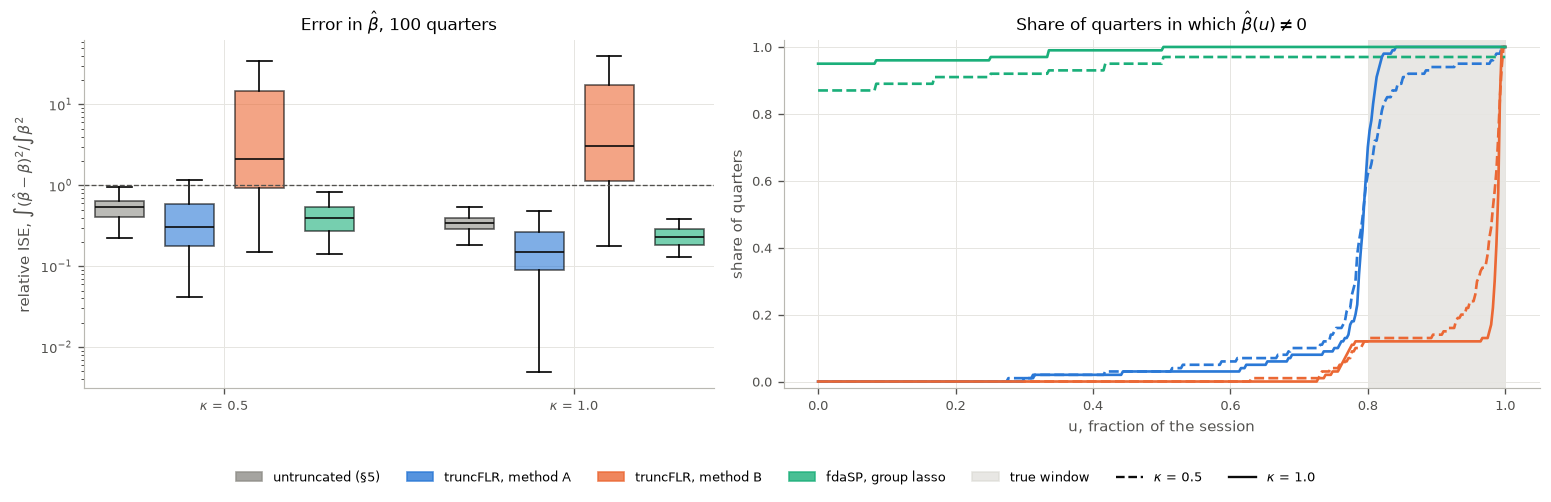

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for i, k in enumerate(mc_kappas):
    for j, m in enumerate(METHODS):
        x = j + i * (len(METHODS) + 1)
        v = mc6.query("kappa == @k and method == @m")["relative ISE"]
        bp = ax.boxplot(v, positions=[x], widths=0.7, showfliers=False, patch_artist=True)
        bp["boxes"][0].set(facecolor=style.METHOD_COLOUR[m], alpha=0.6)
        bp["medians"][0].set(color=style.INK)
ax.set_yscale("log")
ax.axhline(1, color=style.MUTED, lw=0.8, ls="--")
ax.set_xticks([1.5, 6.5], [fr"$\kappa$ = {k}" for k in mc_kappas])
ax.set_ylabel(r"relative ISE, $\int(\hat\beta - \beta)^2 / \int \beta^2$")
ax.set_title(r"Error in $\hat\beta$, 100 quarters")

ax = axes[1]
ax.axvspan(start, 1, color=style.BAND, alpha=0.6, lw=0)
for k, ls in zip(mc_kappas, ("--", "-")):
    for m in ("HH-A", "HH-B", "OGL"):
        freq = np.mean([fit[m]["support"] for fit in mc_fits[k]], axis=0)
        ax.plot(s, freq, color=style.METHOD_COLOUR[m], lw=1.6, ls=ls)
ax.set_ylim(-0.02, 1.02)
ax.set_title(r"Share of quarters in which $\hat\beta(u) \neq 0$")
ax.set_xlabel("u, fraction of the session")
ax.set_ylabel("share of quarters")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=style.METHOD_COLOUR[m], alpha=0.8,
                                  label=LABEL[m]) for m in METHODS]
           + [plt.Rectangle((0, 0), 1, 1, color=style.BAND, alpha=0.6, label="true window")]
           + [plt.Line2D([], [], color=style.INK, ls=ls, label=fr"$\kappa$ = {k}")
              for k, ls in zip(mc_kappas, ("--", "-"))],
           loc="lower center", ncol=7, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_jump_methods_mc")
plt.show()

**Left:** each box spans the quartiles of the relative ISE over the 100 quarters, the whiskers
reach 1.5 interquartile ranges, and outliers are not drawn (the maxima are in the table). The
dashed line at 1 is the error of $\hat\beta \equiv 0$. **Right:** a truncFLR fit is non-zero
exactly on $[\hat u, 1]$, so its curve is the empirical distribution function of $\hat u$; a method
that always found the window would step from 0 to 1 at 0.8. For the group lasso the curve is the
share of quarters in which $\hat\beta$ was not zeroed at $u$.

- **Method A is the most accurate, and the only method that finds the window.** Its median
  relative ISE is 0.152 at $\kappa = 1$ and 0.302 at $\kappa = 0.5$. Its median window start is
  0.795, and the start lies within 0.02 of 0.8 in 77% of quarters at $\kappa = 1$ and in 50% at
  $\kappa = 0.5$. When it fails, it fails badly: its worst quarter at $\kappa = 0.5$ has relative
  ISE 485.5.
- **The group lasso is the most reliable of the sparse methods.** It is second on median error
  (0.231 and 0.392), and its worst quarter (8.085) is far better than method A's. It rarely
  finds the zero region, though: it zeroes any part of the session in only 5% of quarters at
  $\kappa = 1$ and 14% at $\kappa = 0.5$, because cross-validation chooses $\lambda$ for
  prediction error, not for support recovery.
- **The untruncated fit** (median 0.341 and 0.542) loses on median error to both methods above but
  has the shortest tail: its worst quarter is 1.346. Its $M = 8$ was chosen knowing $\beta$
  (§5), which favours it.
- **Method B fails in almost every quarter**, for the reason the scan shows. Its median window
  start is 0.990 at $\kappa = 1$ and 0.982 at $\kappa = 0.5$.

Both truncFLR methods were told that the window ends at the close; the group lasso was told
nothing. `window_jump_power.ipynb` repeats the comparison at $R^2$ of 1% to 5%, on up to a
thousand days.